## BloodMNIST Phase I

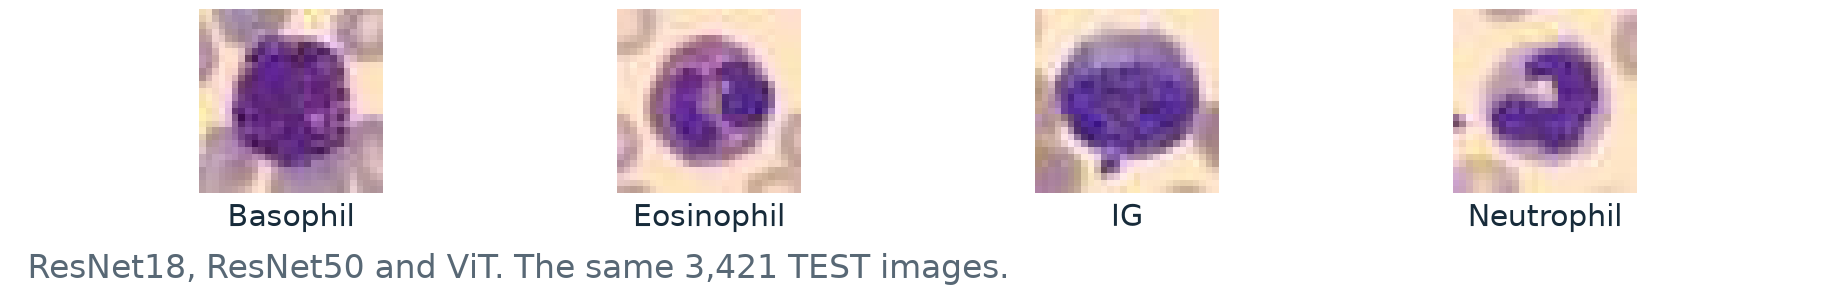

## High accuracy leaves confident mistakes

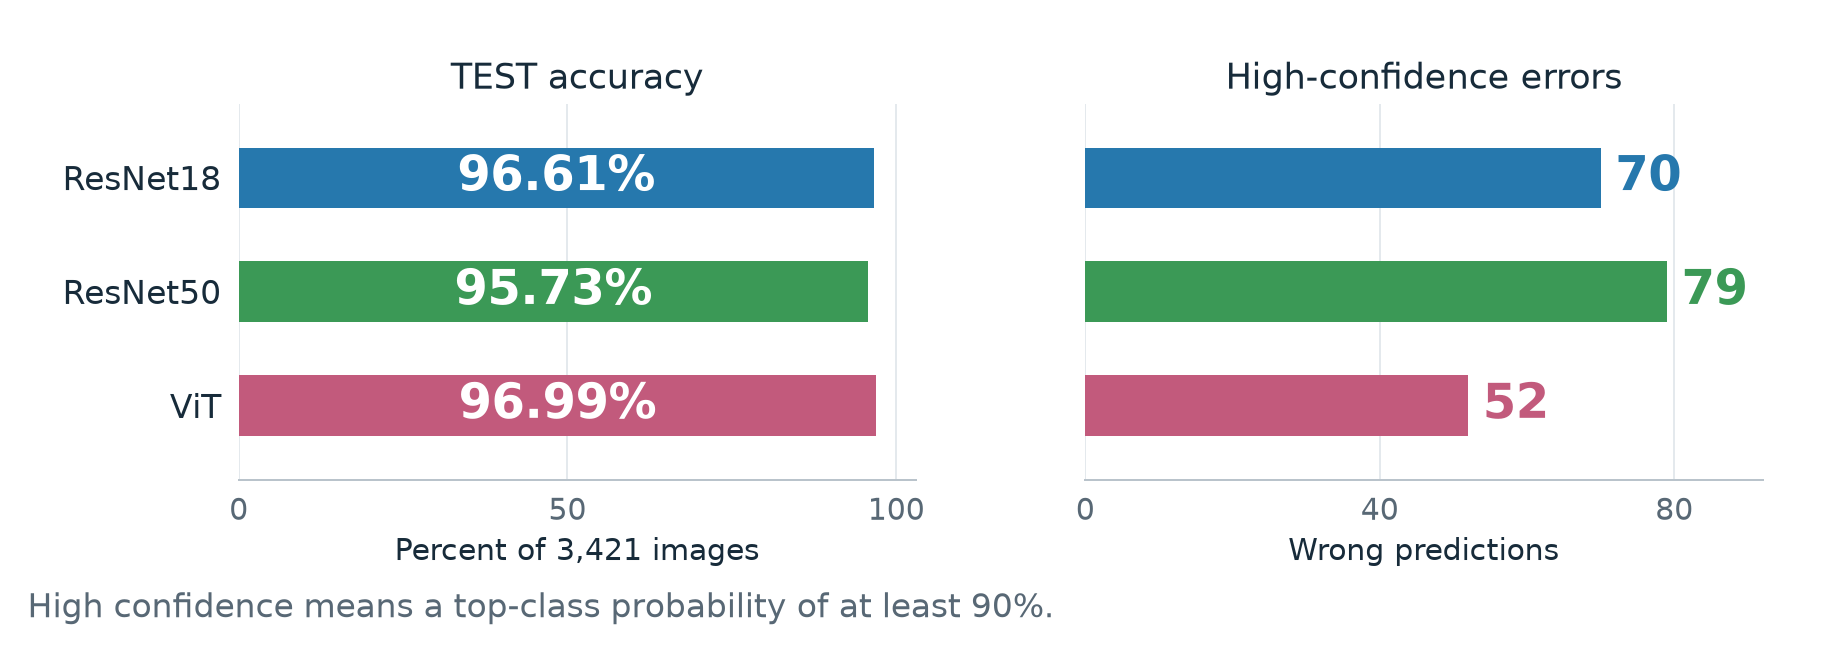

## Even model agreement can be confidently wrong

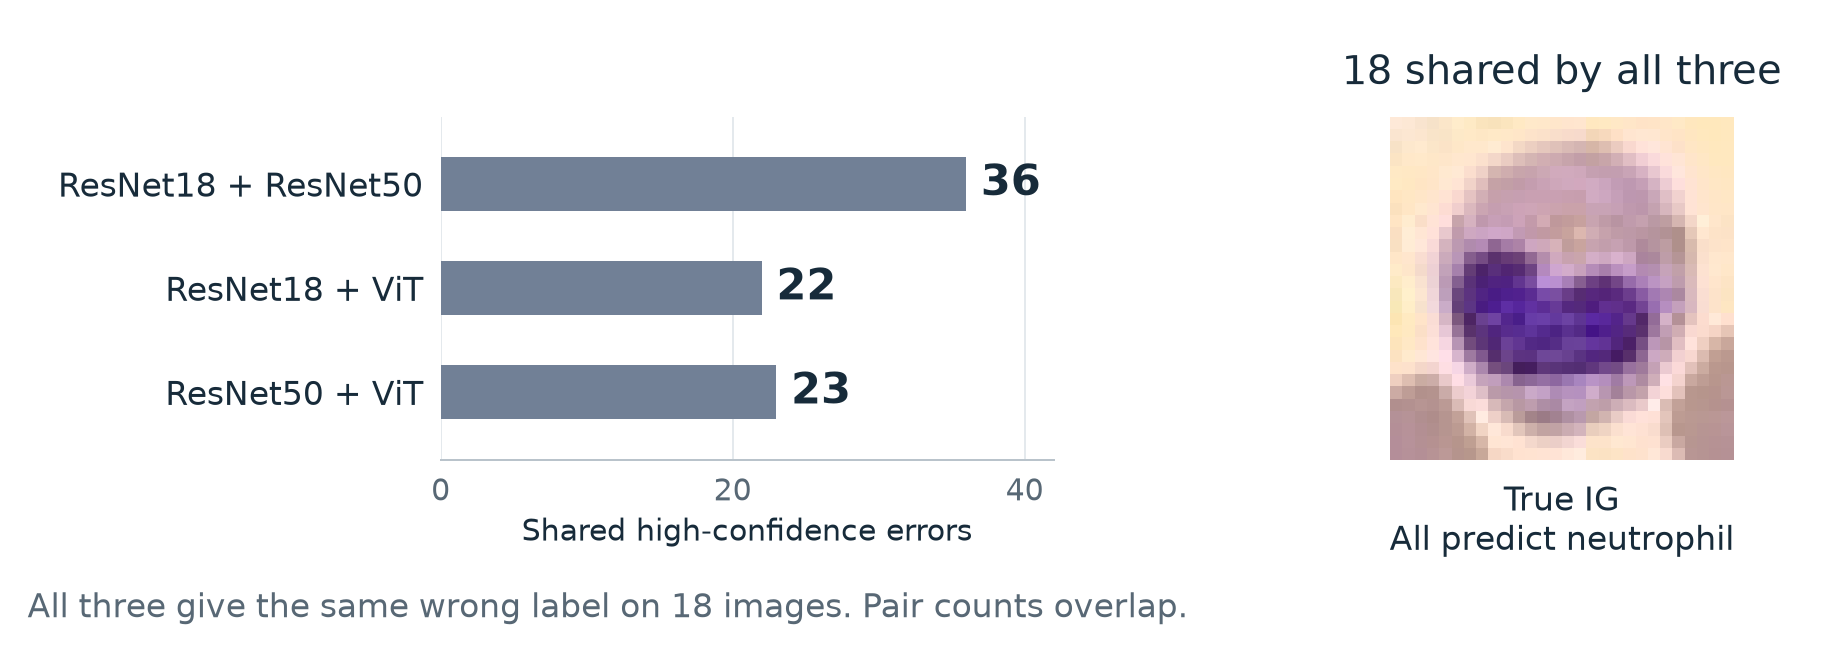

## Many confident mistakes involve immature granulocytes

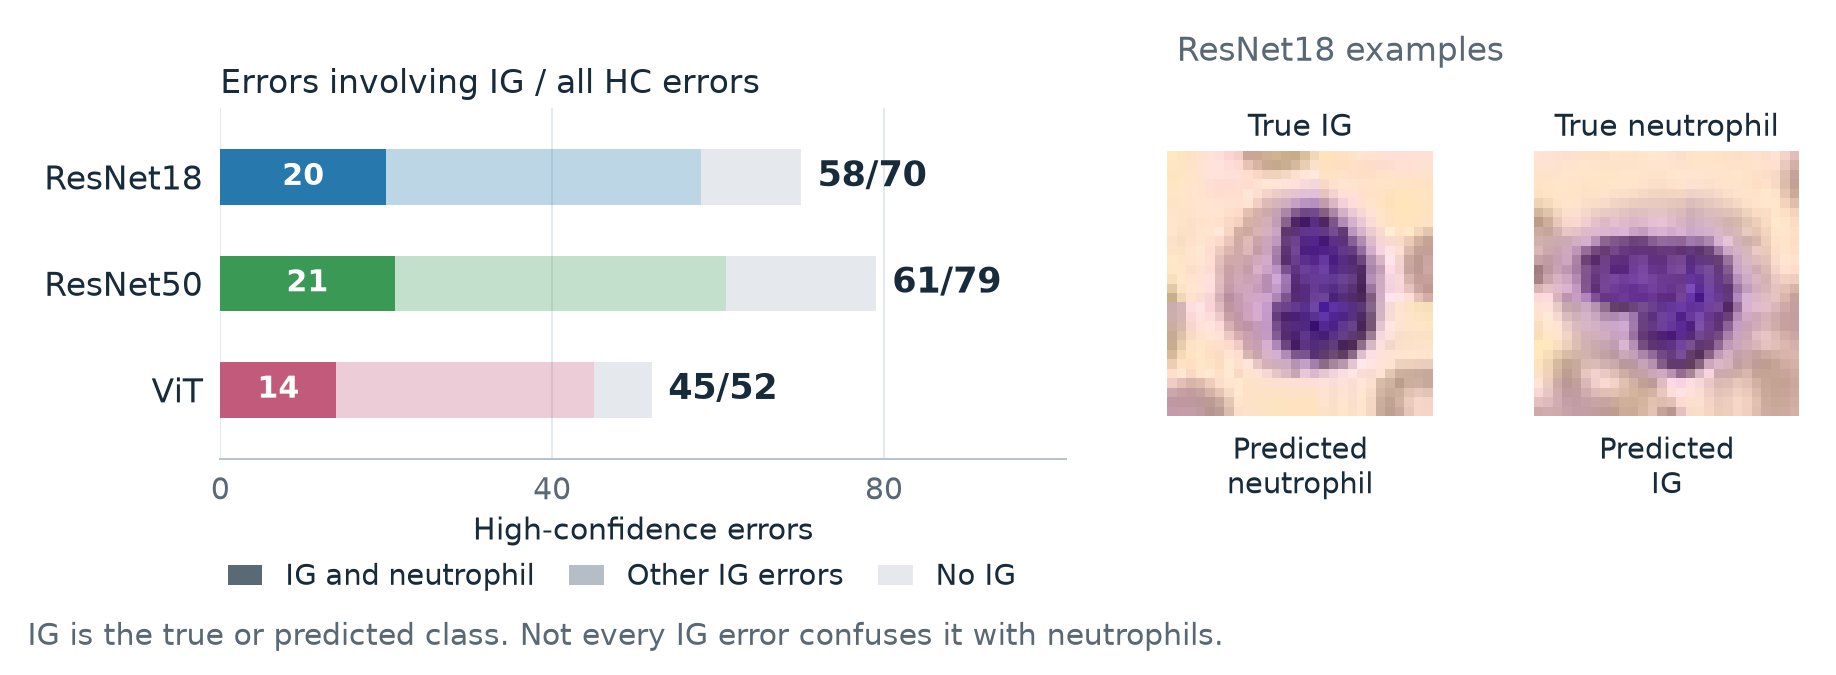

## There is no universal robustness winner

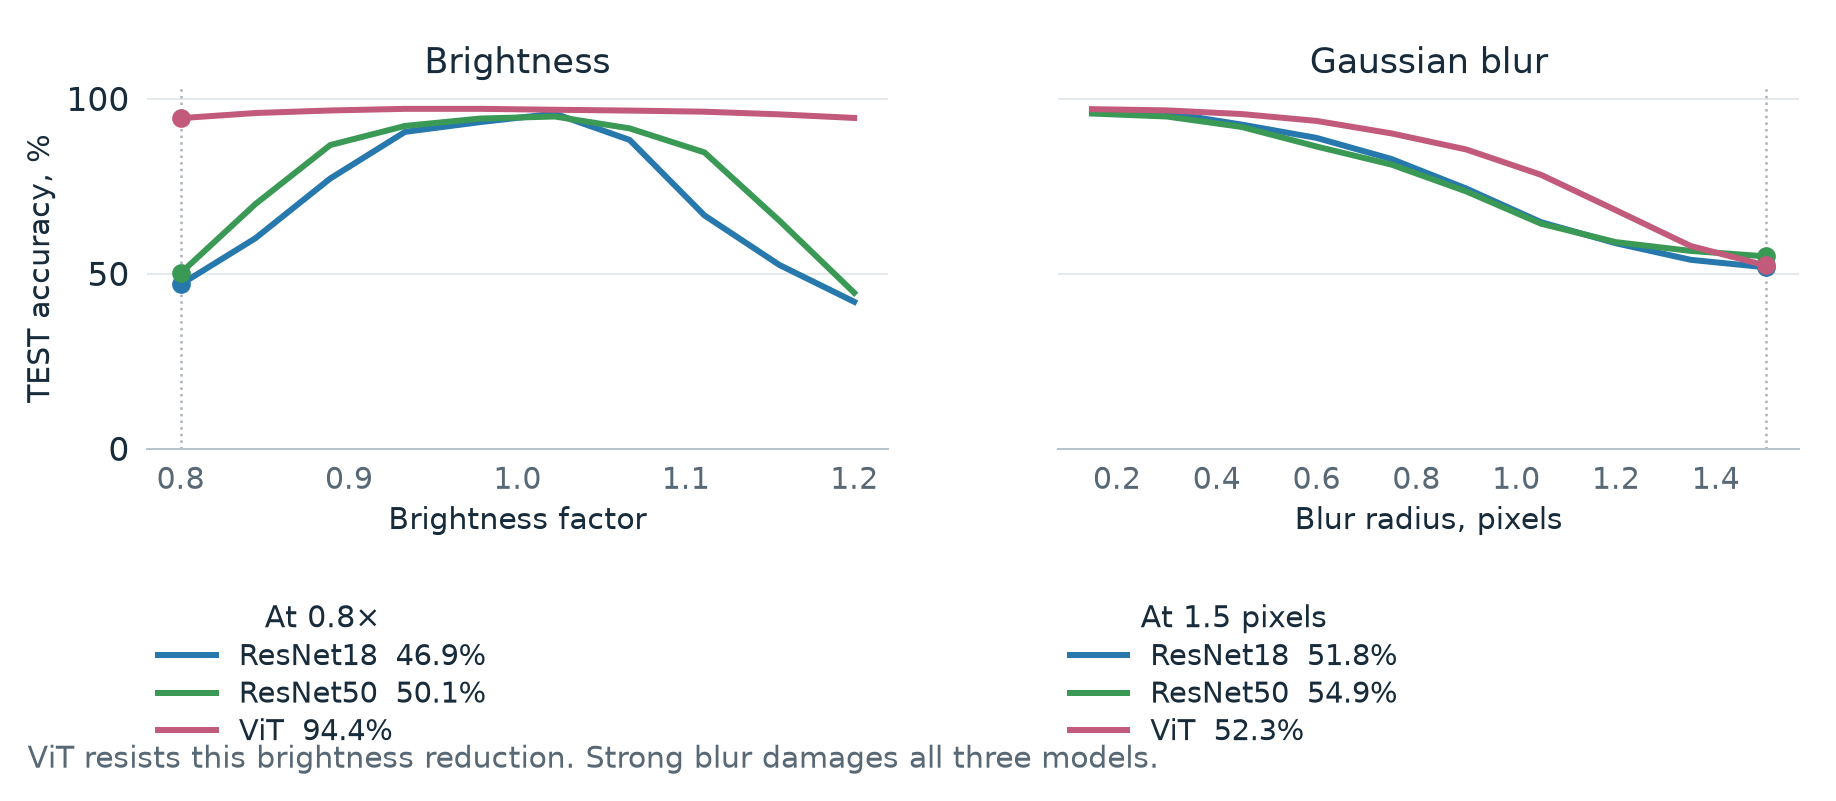

## Explore how input changes create and recover errors

In [1]:

from IPython.display import display
display({'text/html': '<iframe title="Interactive transformation explorer" sandbox="allow-scripts" allow="fullscreen" allowfullscreen style="width:100%;height:430px;border:0;background:white" srcdoc="&lt;!doctype html&gt;\r\n&lt;html lang=&quot;en&quot;&gt;&lt;meta charset=&quot;utf-8&quot;&gt;&lt;meta name=&quot;viewport&quot; content=&quot;width=device-width, initial-scale=1&quot;&gt;\r\n&lt;title&gt;Transformation explorer&lt;/title&gt;\r\n&lt;style&gt;\r\n*{box-sizing:border-box}body{font:14px system-ui,sans-serif;color:#252b32;max-width:1500px;margin:16px auto;padding:0 16px}h1{font-size:21px;margin:0}header,.toolbar,.legend{display:flex;align-items:center;flex-wrap:wrap;gap:12px}header{justify-content:space-between;margin-bottom:16px}.toolbar{gap:10px}label{display:flex;align-items:center;gap:8px;color:#58616b}select,button{font:inherit;background:white;border:1px solid #cfd5db;border-radius:5px;padding:5px 9px;color:#252b32}button{cursor:pointer}button:hover{background:#f1f4f7}button:focus-visible,select:focus-visible{outline:2px solid #2678ad}input{width:155px}output{min-width:94px;font-variant-numeric:tabular-nums}.legend{font-size:12px;color:#58616b;margin-bottom:12px;gap:18px}.swatch{display:inline-block;width:12px;height:9px;margin-right:5px}.models{display:grid;grid-template-columns:repeat(3,minmax(250px,1fr));gap:14px}.card{border:1px solid #e1e5e9;border-radius:7px;padding:12px}.model-head{display:flex;align-items:baseline;justify-content:space-between;gap:6px}.model-head h2{font-size:17px;margin:0}.accuracy{font-size:15px;font-weight:600;white-space:nowrap}.delta{font-size:12px;font-weight:400;color:#69737e;margin-left:6px}svg{width:100%;height:auto;touch-action:none;user-select:none;cursor:crosshair}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;border-top:1px solid #edf0f3;padding-top:8px}.stats span{display:block;color:#69737e;font-size:11px}.stats strong{font-size:17px;font-weight:600;font-variant-numeric:tabular-nums}.footer{display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-top:12px;color:#69737e;font-size:12px}details{margin-top:14px;color:#58616b;font-size:12px;line-height:1.6}summary{cursor:pointer}details p{max-width:1050px}a{color:#17689c}.selection{fill:#2678ad;fill-opacity:.12;stroke:#2678ad;stroke-dasharray:4 3;pointer-events:none}@media(max-width:850px){.models{grid-template-columns:1fr}header{align-items:flex-start}.toolbar{width:100%}}\r\n&lt;/style&gt;&lt;style&gt;\nbody{margin:6px auto;padding:0 8px;font-size:13px}header{margin-bottom:8px;gap:6px}header h1{display:none}.toolbar{gap:7px;width:100%}select,button{padding:4px 7px}input{width:125px}output{min-width:75px}.legend{margin-bottom:8px;gap:12px}.models{grid-template-columns:repeat(3,minmax(0,1fr));gap:10px}.card{padding:7px}.model-head h2{font-size:15px}.accuracy{font-size:14px}.delta{font-size:11px;margin-left:3px}.stats{gap:4px;padding-top:5px}.stats span{font-size:11px}.stats strong{font-size:16px}.footer{margin-top:7px}details{display:none}.models svg text{font-size:13px}\n@media(max-width:850px){.models{grid-template-columns:repeat(3,minmax(0,1fr))}.toolbar{width:100%}}\n:fullscreen{background:white;padding:16px;overflow:auto}\n&lt;/style&gt;\r\n&lt;header&gt;&lt;h1&gt;Transformation explorer&lt;/h1&gt;&lt;div class=&quot;toolbar&quot;&gt;&lt;select id=&quot;transformation&quot; aria-label=&quot;Transformation&quot;&gt;&lt;/select&gt;&lt;label&gt;Level &lt;input id=&quot;level&quot; aria-label=&quot;Transformation level&quot; type=&quot;range&quot; min=&quot;0&quot; max=&quot;9&quot; step=&quot;1&quot; value=&quot;9&quot;&gt;&lt;/label&gt;&lt;output id=&quot;levelLabel&quot; aria-live=&quot;polite&quot;&gt;&lt;/output&gt;&lt;button id=&quot;zoom-in&quot; aria-label=&quot;Zoom in&quot; title=&quot;Zoom into the selected level&quot;&gt;+&lt;/button&gt;&lt;button id=&quot;zoom-out&quot; aria-label=&quot;Zoom out&quot; title=&quot;Zoom out&quot;&gt;−&lt;/button&gt;&lt;button id=&quot;fit&quot; title=&quot;Fit this transformation’s data, using the same axes for all models&quot;&gt;Fit&lt;/button&gt;&lt;button id=&quot;reset&quot; title=&quot;Restore the shared full range&quot;&gt;Reset&lt;/button&gt;&lt;button id=&quot;fullscreen&quot; title=&quot;Expand the explorer&quot;&gt;Full screen&lt;/button&gt;&lt;/div&gt;&lt;/header&gt;\r\n&lt;div class=&quot;legend&quot;&gt;&lt;span&gt;&lt;i class=&quot;swatch&quot; style=&quot;background:#2678ad&quot;&gt;&lt;/i&gt;Recovered&lt;/span&gt;&lt;span&gt;&lt;i class=&quot;swatch&quot; style=&quot;background:#c44e00&quot;&gt;&lt;/i&gt;New: ≥90%&lt;/span&gt;&lt;span&gt;&lt;i class=&quot;swatch&quot; style=&quot;background:#f3bc85&quot;&gt;&lt;/i&gt;New: &amp;lt;90%&lt;/span&gt;&lt;span&gt;━━ Net accuracy change&lt;/span&gt;&lt;/div&gt;\r\n&lt;div id=&quot;models&quot; class=&quot;models&quot;&gt;&lt;/div&gt;\r\n&lt;div class=&quot;footer&quot;&gt;&lt;span id=&quot;status&quot;&gt;&lt;/span&gt;&lt;span&gt;Wheel / drag to zoom · double-click to reset&lt;/span&gt;&lt;/div&gt;\r\n&lt;details&gt;&lt;summary&gt;How to read · definitions · sources&lt;/summary&gt;&lt;p&gt;Bars above zero are originally wrong images that become correct; bars below zero are originally correct images that become wrong. Dark orange identifies new errors with confidence ≥90%. The black line is recovered minus new errors, so it measures the net accuracy change. All contributions use the same full-test denominator, not different correct/wrong group sizes; switches between two wrong labels do not contribute. Header percentages show accuracy at the selected level, with the change from the original prediction beside them; hover for the original accuracy.&lt;/p&gt;&lt;p&gt;Zoom is linked across all three models. Drag a rectangle or use the wheel to zoom, click a bar or move the slider to inspect a level, use Fit for the current transformation’s range, or Reset / double-click for the full range. Changing transformations resets zoom. Noise counts are means of three realizations, not independent extra images. Transformed inputs may leave the data distribution or change the label: these views describe checkpoint responses, not a correction strategy.&lt;/p&gt;&lt;p&gt;Design: &lt;a href=&quot;https://pmc.ncbi.nlm.nih.gov/articles/PMC7733875/&quot;&gt;small multiples&lt;/a&gt; · &lt;a href=&quot;https://data.europa.eu/apps/data-visualisation-guide/the-information-seeking-mantra&quot;&gt;overview, filter, details on demand&lt;/a&gt;.&lt;/p&gt;&lt;/details&gt;\r\n&lt;script&gt;\r\nconst D={&quot;n&quot;: 3421, &quot;threshold&quot;: 0.9, &quot;models&quot;: [&quot;ResNet18&quot;, &quot;ResNet50&quot;, &quot;ViT&quot;], &quot;operations&quot;: {&quot;rotation&quot;: {&quot;name&quot;: &quot;Rotation&quot;, &quot;unit&quot;: &quot;degrees&quot;, &quot;levels&quot;: [-20.0, -15.555555555555555, -11.11111111111111, -6.666666666666666, -2.2222222222222214, 2.2222222222222214, 6.666666666666668, 11.111111111111114, 15.555555555555557, 20.0], &quot;repeats&quot;: 1, &quot;lost&quot;: [[351.0, 285.0, 197.0, 146.0, 118.0, 107.0, 128.0, 154.0, 264.0, 325.0], [691.0, 581.0, 492.0, 291.0, 120.0, 119.0, 266.0, 392.0, 465.0, 668.0], [185.0, 178.0, 150.0, 97.0, 74.0, 67.0, 101.0, 150.0, 161.0, 175.0]], &quot;recovered&quot;: [[58.0, 58.0, 52.0, 44.0, 26.0, 25.0, 36.0, 42.0, 52.0, 60.0], [60.0, 61.0, 55.0, 53.0, 30.0, 30.0, 48.0, 55.0, 57.0, 60.0], [28.0, 28.0, 29.0, 25.0, 21.0, 16.0, 23.0, 30.0, 26.0, 27.0]], &quot;hc_lost&quot;: [[250.0, 187.0, 106.0, 67.0, 55.0, 56.0, 63.0, 82.0, 148.0, 217.0], [546.0, 452.0, 355.0, 180.0, 59.0, 59.0, 156.0, 272.0, 351.0, 547.0], [80.0, 71.0, 65.0, 36.0, 15.0, 13.0, 30.0, 61.0, 62.0, 63.0]]}, &quot;translation&quot;: {&quot;name&quot;: &quot;Translation&quot;, &quot;unit&quot;: &quot;pixels&quot;, &quot;levels&quot;: [-3.0, -2.3333333333333335, -1.6666666666666667, -1.0, -0.3333333333333335, 0.33333333333333304, 1.0, 1.666666666666666, 2.333333333333333, 3.0], &quot;repeats&quot;: 1, &quot;lost&quot;: [[320.0, 221.0, 214.0, 60.0, 122.0, 105.0, 112.0, 334.0, 353.0, 337.0], [730.0, 341.0, 296.0, 56.0, 131.0, 105.0, 159.0, 396.0, 493.0, 868.0], [33.0, 54.0, 58.0, 15.0, 46.0, 51.0, 15.0, 51.0, 54.0, 31.0]], &quot;recovered&quot;: [[57.0, 58.0, 57.0, 42.0, 30.0, 28.0, 53.0, 50.0, 47.0, 43.0], [56.0, 63.0, 62.0, 45.0, 34.0, 36.0, 50.0, 60.0, 59.0, 58.0], [25.0, 15.0, 13.0, 23.0, 10.0, 11.0, 22.0, 18.0, 17.0, 27.0]], &quot;hc_lost&quot;: [[214.0, 144.0, 133.0, 25.0, 56.0, 45.0, 40.0, 138.0, 131.0, 122.0], [429.0, 224.0, 174.0, 23.0, 61.0, 50.0, 90.0, 263.0, 339.0, 670.0], [2.0, 13.0, 10.0, 2.0, 9.0, 9.0, 2.0, 19.0, 14.0, 2.0]]}, &quot;brightness&quot;: {&quot;name&quot;: &quot;Brightness&quot;, &quot;unit&quot;: &quot;factor&quot;, &quot;levels&quot;: [0.8, 0.8444444444444444, 0.888888888888889, 0.9333333333333333, 0.9777777777777777, 1.0222222222222221, 1.0666666666666667, 1.1111111111111112, 1.1555555555555554, 1.2], &quot;repeats&quot;: 1, &quot;lost&quot;: [[1727.0, 1284.0, 704.0, 241.0, 139.0, 57.0, 328.0, 1073.0, 1553.0, 1905.0], [1611.0, 939.0, 367.0, 165.0, 89.0, 46.0, 178.0, 417.0, 1083.0, 1784.0], [119.0, 66.0, 39.0, 17.0, 6.0, 9.0, 23.0, 39.0, 70.0, 111.0]], &quot;recovered&quot;: [[26.0, 35.0, 39.0, 32.0, 25.0, 26.0, 40.0, 47.0, 43.0, 35.0], [50.0, 54.0, 59.0, 44.0, 40.0, 17.0, 33.0, 37.0, 36.0, 32.0], [31.0, 28.0, 26.0, 20.0, 9.0, 3.0, 9.0, 14.0, 19.0, 25.0]], &quot;hc_lost&quot;: [[1206.0, 882.0, 434.0, 139.0, 70.0, 23.0, 233.0, 725.0, 1124.0, 1530.0], [1334.0, 702.0, 232.0, 102.0, 40.0, 7.0, 82.0, 236.0, 621.0, 1134.0], [50.0, 25.0, 10.0, 1.0, 0.0, 0.0, 1.0, 5.0, 15.0, 30.0]]}, &quot;blur&quot;: {&quot;name&quot;: &quot;Blur&quot;, &quot;unit&quot;: &quot;pixels&quot;, &quot;levels&quot;: [0.15, 0.30000000000000004, 0.45000000000000007, 0.6000000000000001, 0.7500000000000001, 0.9000000000000001, 1.05, 1.2000000000000002, 1.35, 1.5], &quot;repeats&quot;: 1, &quot;lost&quot;: [[1.0, 41.0, 166.0, 301.0, 505.0, 795.0, 1124.0, 1331.0, 1493.0, 1566.0], [0.0, 47.0, 167.0, 363.0, 544.0, 809.0, 1119.0, 1296.0, 1380.0, 1437.0], [0.0, 20.0, 58.0, 130.0, 256.0, 417.0, 667.0, 1010.0, 1359.0, 1547.0]], &quot;recovered&quot;: [[0.0, 19.0, 28.0, 33.0, 31.0, 32.0, 32.0, 33.0, 33.0, 33.0], [0.0, 18.0, 36.0, 41.0, 45.0, 48.0, 42.0, 39.0, 37.0, 41.0], [0.0, 8.0, 10.0, 15.0, 19.0, 23.0, 25.0, 22.0, 21.0, 19.0]], &quot;hc_lost&quot;: [[0.0, 9.0, 90.0, 197.0, 324.0, 491.0, 668.0, 812.0, 949.0, 1074.0], [0.0, 11.0, 93.0, 223.0, 355.0, 511.0, 698.0, 830.0, 900.0, 949.0], [0.0, 3.0, 17.0, 46.0, 117.0, 220.0, 307.0, 445.0, 603.0, 733.0]]}, &quot;noise&quot;: {&quot;name&quot;: &quot;Noise&quot;, &quot;unit&quot;: &quot;sigma&quot;, &quot;levels&quot;: [0.01, 0.020000000000000004, 0.030000000000000006, 0.04000000000000001, 0.05000000000000001, 0.06000000000000001, 0.07, 0.08, 0.09000000000000001, 0.1], &quot;repeats&quot;: 3, &quot;lost&quot;: [[11.666666666666664, 33.0, 67.66666666666666, 117.66666666666666, 210.66666666666666, 343.66666666666663, 525.0, 767.0, 1082.6666666666665, 1438.6666666666665], [13.333333333333332, 32.666666666666664, 58.0, 111.0, 204.0, 372.0, 583.3333333333333, 860.3333333333333, 1178.3333333333335, 1519.3333333333335], [6.666666666666666, 9.999999999999998, 18.666666666666664, 29.666666666666664, 38.0, 52.0, 70.66666666666666, 94.66666666666666, 127.33333333333331, 162.33333333333331]], &quot;recovered&quot;: [[11.666666666666664, 18.666666666666664, 31.666666666666664, 35.666666666666664, 43.0, 44.0, 46.0, 45.33333333333333, 36.0, 28.999999999999996], [11.0, 17.666666666666664, 26.999999999999996, 32.33333333333333, 37.666666666666664, 41.33333333333333, 36.0, 34.33333333333333, 25.0, 22.333333333333332], [11.333333333333332, 17.666666666666664, 28.33333333333333, 30.333333333333332, 34.666666666666664, 41.33333333333333, 43.0, 39.0, 45.33333333333333, 37.33333333333333]], &quot;hc_lost&quot;: [[0.3333333333333333, 5.333333333333333, 28.999999999999996, 63.33333333333333, 118.66666666666666, 207.66666666666663, 323.66666666666663, 470.3333333333333, 691.3333333333333, 952.0], [1.0, 5.666666666666666, 14.333333333333332, 49.33333333333333, 104.33333333333333, 215.0, 352.0, 537.3333333333333, 786.0, 1046.0], [0.0, 0.3333333333333333, 3.6666666666666665, 6.333333333333333, 10.333333333333332, 16.666666666666664, 27.333333333333332, 41.0, 57.666666666666664, 68.33333333333333]]}, &quot;green_scale&quot;: {&quot;name&quot;: &quot;Green scaling&quot;, &quot;unit&quot;: &quot;factor&quot;, &quot;levels&quot;: [0.9, 0.9222222222222223, 0.9444444444444445, 0.9666666666666667, 0.9888888888888889, 1.011111111111111, 1.0333333333333334, 1.0555555555555556, 1.077777777777778, 1.1], &quot;repeats&quot;: 1, &quot;lost&quot;: [[2013.0, 1471.0, 783.0, 226.0, 31.0, 11.0, 61.0, 143.0, 341.0, 604.0], [785.0, 464.0, 225.0, 81.0, 14.0, 21.0, 83.0, 166.0, 281.0, 524.0], [10.0, 8.0, 5.0, 2.0, 3.0, 1.0, 9.0, 10.0, 16.0, 19.0]], &quot;recovered&quot;: [[14.0, 15.0, 17.0, 21.0, 13.0, 8.0, 14.0, 26.0, 29.0, 26.0], [24.0, 27.0, 29.0, 27.0, 12.0, 10.0, 27.0, 42.0, 44.0, 45.0], [15.0, 12.0, 10.0, 6.0, 1.0, 0.0, 1.0, 6.0, 8.0, 9.0]], &quot;hc_lost&quot;: [[1781.0, 1234.0, 612.0, 149.0, 8.0, 0.0, 21.0, 51.0, 127.0, 277.0], [582.0, 321.0, 130.0, 32.0, 0.0, 0.0, 25.0, 66.0, 133.0, 221.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]]}, &quot;red_scale&quot;: {&quot;name&quot;: &quot;Red scaling&quot;, &quot;unit&quot;: &quot;factor&quot;, &quot;levels&quot;: [0.9, 0.9222222222222223, 0.9444444444444445, 0.9666666666666667, 0.9888888888888889, 1.011111111111111, 1.0333333333333334, 1.0555555555555556, 1.077777777777778, 1.1], &quot;repeats&quot;: 1, &quot;lost&quot;: [[1277.0, 719.0, 319.0, 119.0, 33.0, 38.0, 154.0, 337.0, 724.0, 1538.0], [1285.0, 1016.0, 652.0, 236.0, 59.0, 41.0, 150.0, 282.0, 510.0, 1029.0], [37.0, 27.0, 20.0, 15.0, 4.0, 4.0, 12.0, 21.0, 29.0, 37.0]], &quot;recovered&quot;: [[25.0, 29.0, 28.0, 26.0, 16.0, 24.0, 43.0, 45.0, 46.0, 35.0], [57.0, 50.0, 41.0, 37.0, 27.0, 20.0, 38.0, 41.0, 41.0, 37.0], [11.0, 9.0, 7.0, 6.0, 0.0, 5.0, 13.0, 19.0, 23.0, 24.0]], &quot;hc_lost&quot;: [[694.0, 313.0, 95.0, 44.0, 6.0, 13.0, 88.0, 233.0, 548.0, 1233.0], [755.0, 584.0, 282.0, 137.0, 19.0, 6.0, 85.0, 185.0, 339.0, 723.0], [7.0, 3.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 5.0, 9.0]]}, &quot;blue_scale&quot;: {&quot;name&quot;: &quot;Blue scaling&quot;, &quot;unit&quot;: &quot;factor&quot;, &quot;levels&quot;: [0.9, 0.9222222222222223, 0.9444444444444445, 0.9666666666666667, 0.9888888888888889, 1.011111111111111, 1.0333333333333334, 1.0555555555555556, 1.077777777777778, 1.1], &quot;repeats&quot;: 1, &quot;lost&quot;: [[493.0, 271.0, 139.0, 60.0, 15.0, 11.0, 42.0, 85.0, 140.0, 207.0], [339.0, 197.0, 98.0, 38.0, 8.0, 12.0, 37.0, 65.0, 106.0, 144.0], [22.0, 18.0, 11.0, 5.0, 4.0, 7.0, 13.0, 24.0, 28.0, 42.0]], &quot;recovered&quot;: [[52.0, 49.0, 39.0, 29.0, 12.0, 6.0, 16.0, 21.0, 25.0, 31.0], [45.0, 42.0, 33.0, 27.0, 10.0, 5.0, 9.0, 19.0, 25.0, 31.0], [29.0, 28.0, 25.0, 14.0, 2.0, 0.0, 3.0, 5.0, 7.0, 12.0]], &quot;hc_lost&quot;: [[353.0, 177.0, 73.0, 21.0, 1.0, 0.0, 7.0, 27.0, 64.0, 110.0], [229.0, 119.0, 48.0, 15.0, 0.0, 0.0, 7.0, 26.0, 44.0, 66.0], [6.0, 3.0, 2.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0, 4.0]]}}, &quot;baseline_accuracy&quot;: [96.60917860274773, 95.73224203449284, 96.98918444899152], &quot;baseline_errors&quot;: [116, 146, 103], &quot;ymin&quot;: -60.0, &quot;ymax&quot;: 5.0};\r\nconst select=document.getElementById(&#x27;transformation&#x27;), slider=document.getElementById(&#x27;level&#x27;);\r\nfor(const [key,p] of Object.entries(D.operations)){const o=document.createElement(&#x27;option&#x27;);o.value=key;o.textContent=p.name;select.append(o);}\r\nconst G={W:400,H:270,L:42,R:10,T:20,B:38};G.w=G.W-G.L-G.R;G.h=G.H-G.T-G.B;\r\nconst full={xmin:-.5,xmax:9.5,ymin:D.ymin,ymax:D.ymax};let view={...full},chosen=9,suppressClickUntil=0;\r\nconst fmt=x=&gt;Math.abs(x)&lt;1e-9?&#x27;0&#x27;:Number(x.toPrecision(3)).toString();\r\nconst count=x=&gt;Math.abs(x-Math.round(x))&lt;1e-6?Math.round(x).toLocaleString():x.toFixed(1);\r\nconst pp=x=&gt;(x&gt;=0?&#x27;+&#x27;:&#x27;&#x27;)+x.toFixed(1)+&#x27; pp&#x27;;\r\nconst X=j=&gt;G.L+(j-view.xmin)/(view.xmax-view.xmin)*G.w;\r\nconst Y=v=&gt;G.T+(view.ymax-v)/(view.ymax-view.ymin)*G.h;\r\nconst invX=x=&gt;view.xmin+(x-G.L)/G.w*(view.xmax-view.xmin);\r\nconst invY=y=&gt;view.ymax-(y-G.T)/G.h*(view.ymax-view.ymin);\r\nfunction bounded(lo,hi,min,max,minSpan){const span=Math.min(max-min,Math.max(minSpan,hi-lo));lo=Math.max(min,Math.min((lo+hi-span)/2,max-span));return[lo,lo+span];}\r\nfunction setView(xmin,xmax,ymin,ymax){[view.xmin,view.xmax]=bounded(xmin,xmax,full.xmin,full.xmax,1.5);[view.ymin,view.ymax]=bounded(ymin,ymax,full.ymin,full.ymax,.5);if(chosen&lt;view.xmin||chosen&gt;view.xmax){chosen=Math.max(0,Math.min(9,Math.round((view.xmin+view.xmax)/2)));slider.value=chosen;}render();}\r\nfunction zoom(factor,cx=chosen,cy=0){setView(cx+(view.xmin-cx)*factor,cx+(view.xmax-cx)*factor,cy+(view.ymin-cy)*factor,cy+(view.ymax-cy)*factor);}\r\nfunction reset(){view={...full};render();}\r\nfunction ticks(lo,hi){const raw=(hi-lo)/5,power=10**Math.floor(Math.log10(raw)),r=raw/power,step=(r&lt;=1?1:r&lt;=2?2:r&lt;=5?5:10)*power,result=[];for(let v=Math.ceil(lo/step)*step;v&lt;=hi+step*1e-8;v+=step)result.push(v);return result;}\r\nfunction chart(p,m){\r\n const dx=G.w/(view.xmax-view.xmin),clip=`clip${m}`;\r\n let s=`&lt;svg viewBox=&quot;0 0 ${G.W} ${G.H}&quot; data-model=&quot;${m}&quot; role=&quot;img&quot; aria-label=&quot;${D.models[m]}: zoomable accuracy contributions&quot;&gt;&lt;defs&gt;&lt;clipPath id=&quot;${clip}&quot;&gt;&lt;rect x=&quot;${G.L}&quot; y=&quot;${G.T}&quot; width=&quot;${G.w}&quot; height=&quot;${G.h}&quot;/&gt;&lt;/clipPath&gt;&lt;/defs&gt;`;\r\n s+=`&lt;g clip-path=&quot;url(#${clip})&quot;&gt;&lt;rect x=&quot;${X(chosen)-dx/2}&quot; y=&quot;${G.T}&quot; width=&quot;${dx}&quot; height=&quot;${G.h}&quot; fill=&quot;#f5f7fa&quot;/&gt;&lt;/g&gt;`;\r\n for(const tick of ticks(view.ymin,view.ymax))s+=`&lt;line x1=&quot;${G.L}&quot; x2=&quot;${G.W-G.R}&quot; y1=&quot;${Y(tick)}&quot; y2=&quot;${Y(tick)}&quot; stroke=&quot;${Math.abs(tick)&lt;1e-8?&#x27;#969fa9&#x27;:&#x27;#edf0f3&#x27;}&quot;/&gt;&lt;text x=&quot;${G.L-6}&quot; y=&quot;${Y(tick)+4}&quot; text-anchor=&quot;end&quot; font-size=&quot;11&quot; fill=&quot;#69737e&quot;&gt;${fmt(tick)}&lt;/text&gt;`;\r\n s+=`&lt;text x=&quot;${G.L}&quot; y=&quot;12&quot; font-size=&quot;10&quot; fill=&quot;#69737e&quot;&gt;Accuracy contributions (pp)&lt;/text&gt;&lt;g clip-path=&quot;url(#${clip})&quot;&gt;`;\r\n for(let j=0;j&lt;10;j++){\r\n  const gain=100*p.recovered[m][j]/D.n,loss=100*p.lost[m][j]/D.n,hc=100*p.hc_lost[m][j]/D.n,a=X(j)-.33*dx,b=.66*dx;\r\n  s+=`&lt;g data-step=&quot;${j}&quot; style=&quot;cursor:pointer&quot;&gt;&lt;title&gt;${p.name} ${fmt(p.levels[j])} ${p.unit}: ${count(p.lost[m][j])} new (${count(p.hc_lost[m][j])} confident); ${count(p.recovered[m][j])} recovered&lt;/title&gt;&lt;rect x=&quot;${X(j)-dx/2}&quot; y=&quot;${G.T}&quot; width=&quot;${dx}&quot; height=&quot;${G.h}&quot; fill=&quot;transparent&quot;/&gt;&lt;rect x=&quot;${a}&quot; y=&quot;${Y(gain)}&quot; width=&quot;${b}&quot; height=&quot;${Y(0)-Y(gain)}&quot; fill=&quot;#2678ad&quot;/&gt;&lt;rect x=&quot;${a}&quot; y=&quot;${Y(0)}&quot; width=&quot;${b}&quot; height=&quot;${Y(-hc)-Y(0)}&quot; fill=&quot;#c44e00&quot;/&gt;&lt;rect x=&quot;${a}&quot; y=&quot;${Y(-hc)}&quot; width=&quot;${b}&quot; height=&quot;${Y(-loss)-Y(-hc)}&quot; fill=&quot;#f3bc85&quot;/&gt;&lt;/g&gt;`;\r\n }\r\n const points=p.levels.map((_,j)=&gt;`${X(j)},${Y(100*(p.recovered[m][j]-p.lost[m][j])/D.n)}`).join(&#x27; &#x27;);\r\n s+=`&lt;polyline points=&quot;${points}&quot; fill=&quot;none&quot; stroke=&quot;#222&quot; stroke-width=&quot;2&quot; pointer-events=&quot;none&quot;/&gt;&lt;circle cx=&quot;${X(chosen)}&quot; cy=&quot;${Y(100*(p.recovered[m][chosen]-p.lost[m][chosen])/D.n)}&quot; r=&quot;4&quot; fill=&quot;#222&quot; pointer-events=&quot;none&quot;/&gt;&lt;/g&gt;`;\r\n const first=Math.max(0,Math.ceil(view.xmin)),last=Math.min(9,Math.floor(view.xmax)),stride=Math.max(1,Math.ceil((last-first+1)/6));\r\n for(let j=first;j&lt;=last;j++)if((j-first)%stride===0||j===last||j===chosen)s+=`&lt;text x=&quot;${X(j)}&quot; y=&quot;${G.H-20}&quot; text-anchor=&quot;middle&quot; font-size=&quot;10&quot; fill=&quot;#69737e&quot;&gt;${fmt(p.levels[j])}&lt;/text&gt;`;\r\n return s+`&lt;text x=&quot;${G.L+G.w/2}&quot; y=&quot;${G.H-3}&quot; text-anchor=&quot;middle&quot; font-size=&quot;10&quot; fill=&quot;#69737e&quot;&gt;${p.unit}&lt;/text&gt;&lt;/svg&gt;`;\r\n}\r\nfunction localPoint(svg,e){const p=svg.createSVGPoint();p.x=e.clientX;p.y=e.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());}\r\nfunction inside(p){return p.x&gt;=G.L&amp;&amp;p.x&lt;=G.W-G.R&amp;&amp;p.y&gt;=G.T&amp;&amp;p.y&lt;=G.H-G.B;}\r\nfunction bindZoom(svg){\r\n svg.addEventListener(&#x27;wheel&#x27;,e=&gt;{const p=localPoint(svg,e);if(!inside(p))return;e.preventDefault();zoom(Math.exp(Math.max(-1,Math.min(1,e.deltaY*.002))),invX(p.x),invY(p.y));},{passive:false});\r\n svg.ondblclick=e=&gt;{e.preventDefault();reset();};\r\n svg.onclick=e=&gt;{if(Date.now()&lt;suppressClickUntil)return;const p=localPoint(svg,e);if(inside(p)){chosen=Math.max(0,Math.min(9,Math.round(invX(p.x))));slider.value=chosen;render();}};\r\n let start=null,box=null;\r\n svg.onpointerdown=e=&gt;{const p=localPoint(svg,e);if(e.button!==0||!inside(p))return;e.preventDefault();start=p;try{svg.setPointerCapture(e.pointerId);}catch{}box=document.createElementNS(&#x27;http://www.w3.org/2000/svg&#x27;,&#x27;rect&#x27;);box.setAttribute(&#x27;class&#x27;,&#x27;selection&#x27;);svg.append(box);};\r\n svg.onpointermove=e=&gt;{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y));for(const[k,v]of Object.entries({x:Math.min(start.x,x),y:Math.min(start.y,y),width:Math.abs(x-start.x),height:Math.abs(y-start.y)}))box.setAttribute(k,v);};\r\n svg.onpointerup=e=&gt;{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y)),a=start;start=null;box.remove();if(Math.abs(x-a.x)&gt;6&amp;&amp;Math.abs(y-a.y)&gt;6){suppressClickUntil=Date.now()+250;setView(invX(Math.min(x,a.x)),invX(Math.max(x,a.x)),invY(Math.max(y,a.y)),invY(Math.min(y,a.y)));}};\r\n svg.onpointercancel=()=&gt;{start=null;if(box)box.remove();};\r\n}\r\nfunction render(){\r\n const p=D.operations[select.value],j=chosen;document.getElementById(&#x27;levelLabel&#x27;).textContent=fmt(p.levels[j])+&#x27; &#x27;+p.unit;\r\n document.getElementById(&#x27;models&#x27;).innerHTML=D.models.map((name,m)=&gt;{const net=100*(p.recovered[m][j]-p.lost[m][j])/D.n,accuracy=D.baseline_accuracy[m]+net;return `&lt;section class=&quot;card&quot;&gt;&lt;div class=&quot;model-head&quot;&gt;&lt;h2&gt;${name}&lt;/h2&gt;&lt;span class=&quot;accuracy&quot; title=&quot;Original: ${D.baseline_accuracy[m].toFixed(1)}%; ${D.baseline_errors[m]} errors&quot;&gt;${accuracy.toFixed(1)}%&lt;span class=&quot;delta&quot;&gt;${pp(net)}&lt;/span&gt;&lt;/span&gt;&lt;/div&gt;${chart(p,m)}&lt;div class=&quot;stats&quot;&gt;&lt;div&gt;&lt;span&gt;New errors&lt;/span&gt;&lt;strong&gt;${count(p.lost[m][j])}&lt;/strong&gt;&lt;/div&gt;&lt;div&gt;&lt;span&gt;≥90% confident&lt;/span&gt;&lt;strong&gt;${count(p.hc_lost[m][j])}&lt;/strong&gt;&lt;/div&gt;&lt;div&gt;&lt;span&gt;Recovered&lt;/span&gt;&lt;strong&gt;${count(p.recovered[m][j])}&lt;/strong&gt;&lt;/div&gt;&lt;/div&gt;&lt;/section&gt;`;}).join(&#x27;&#x27;);\r\n document.querySelectorAll(&#x27;svg&#x27;).forEach(bindZoom);\r\n const zoomed=Object.keys(full).some(k=&gt;Math.abs(view[k]-full[k])&gt;1e-7);\r\n document.getElementById(&#x27;status&#x27;).textContent=`${D.n.toLocaleString()} TEST images · linked axes · ${zoomed?&#x27;zoomed&#x27;:&#x27;full range&#x27;}`+(p.repeats===3?&#x27; · counts averaged over 3 noise realizations&#x27;:&#x27;&#x27;);\r\n}\r\nselect.onchange=reset;slider.oninput=()=&gt;{chosen=Number(slider.value);render();};\r\ndocument.getElementById(&#x27;zoom-in&#x27;).onclick=()=&gt;zoom(.65);document.getElementById(&#x27;zoom-out&#x27;).onclick=()=&gt;zoom(1.6,(view.xmin+view.xmax)/2,(view.ymin+view.ymax)/2);\r\ndocument.getElementById(&#x27;reset&#x27;).onclick=reset;\r\ndocument.getElementById(&#x27;fit&#x27;).onclick=()=&gt;{const p=D.operations[select.value],lo=-100*Math.max(...p.lost.flat())/D.n,hi=100*Math.max(...p.recovered.flat())/D.n,pad=Math.max(1,(hi-lo)*.08);setView(full.xmin,full.xmax,Math.max(full.ymin,lo-pad),Math.min(full.ymax,hi+pad));};\r\nrender();\r\ndocument.getElementById(&#x27;fullscreen&#x27;).onclick=()=&gt;{if(document.fullscreenElement){document.exitFullscreen();}else{document.documentElement.requestFullscreen();}};\n&lt;/script&gt;&lt;/html&gt;\r\n"></iframe>', 'text/plain': 'Interactive transformation explorer'}, raw=True)

Interactive transformation explorer

## Preprocessing changes the robustness comparison

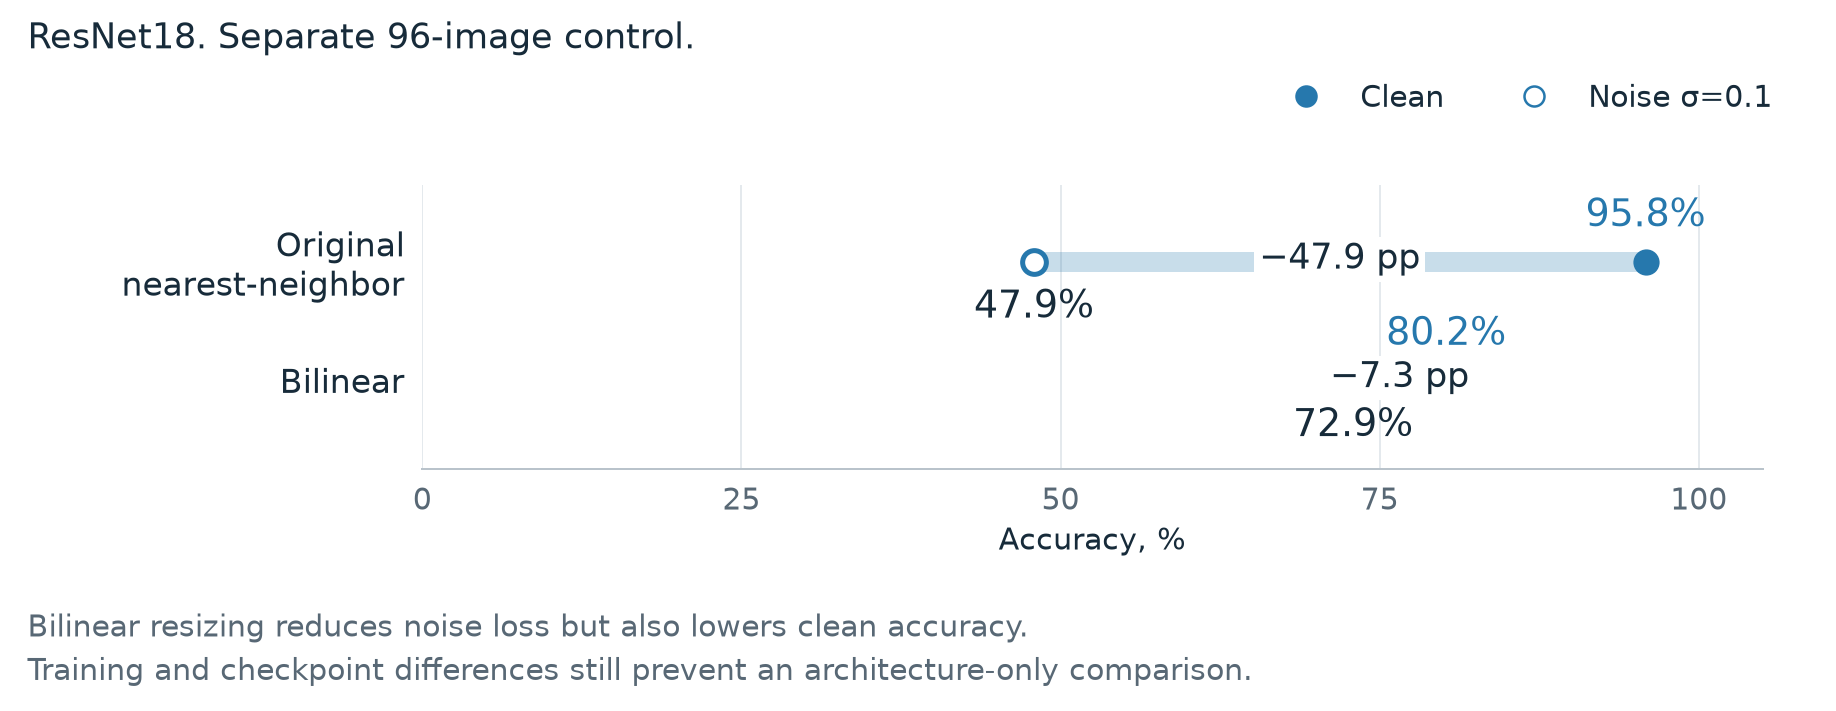

## IG mistakes show patterns, not proven causes

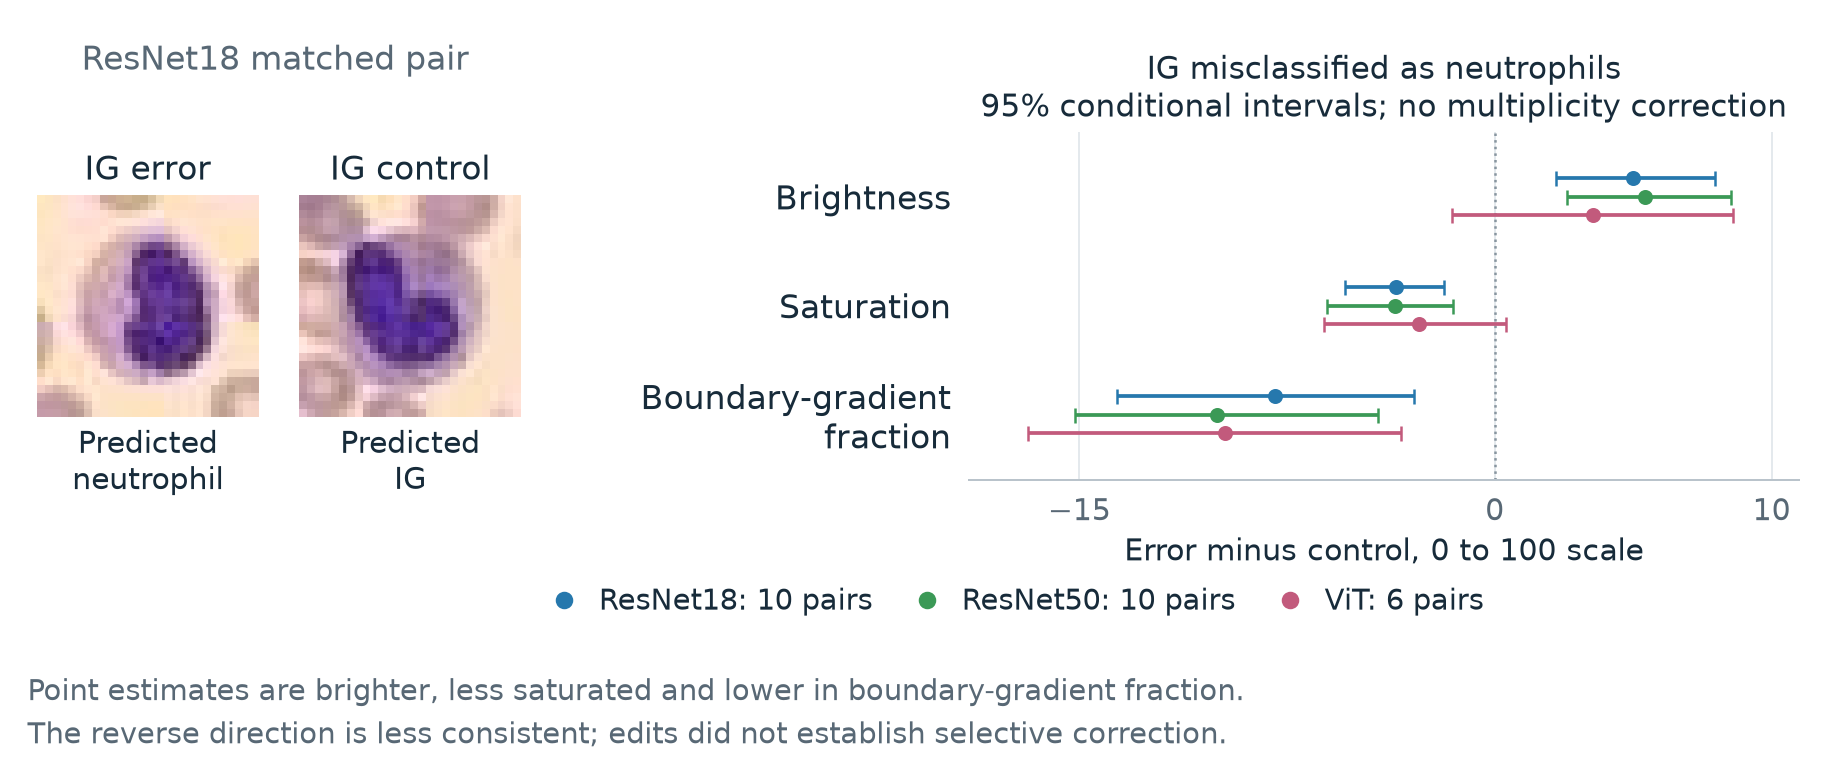

## What high accuracy leaves out

### Confident failures can be shared across models.

### Robustness depends on input changes and preprocessing.

### IG and neutrophil errors show unexplained appearance patterns.